# Nicheformer Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 04.12.2024
- Date of Last Modification: 06.04.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nicheformer uv environment, installable from ```../../envs/nicheformer.sh```.
- Clone Nicheformer from GitHub into ```<root>/analysis/benchmarking```: ```git clone https://github.com/theislab/nicheformer```.
- Download the pretrained model weights from https://data.mendeley.com/preview/87gm9hrgm8?a=d95a6dde-e054-4245-a7eb-0522d6ea7dff as described at https://github.com/theislab/nicheformer/blob/main/README.md and put them into the ```./nicheformer/data``` directory.
- For zero shot inference, this notebooks follows the notebook from https://github.com/theislab/nicheformer/blob/main/notebooks/experiments/get_embeddings.ipynb

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")
sys.path.append("../benchmarking/nicheformer/src")

In [50]:
import os
import warnings
from tqdm import tqdm
from typing import Optional, Dict, Any

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pytorch_lightning as pl
import scanpy as sc
import sklearn.metrics as skm
import torch
from torch.utils.data import DataLoader
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from nicheformer.data import NicheformerDataset
from nicheformer.models import Nicheformer

from analysis_utils import *

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
nicheformer_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/analysis/benchmarking/nicheformer'

BASE_PATH = f'{nicheformer_folder_path}/data/model_means'

### 1.3 Define Config

In [5]:
method = 'nicheformer'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# Nicheformer params
config = {
    'data_path': f'{artifacts_folder_path}/nicheformer/{dataset_name}.h5ad',
    'technology_mean_path': f"{BASE_PATH}/merfish_mean_script.npy", #'path/to/technology_mean.npy',  # Path to technology mean file
    'checkpoint_path': f'{nicheformer_folder_path}/data/nicheformer.ckpt',  # Path to model checkpoint
    'output_path': f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad',  # Where to save the result, it is a new h5ad
    'output_dir': '.',  # Directory for any intermediate outputs
    'batch_size': 32,
    'max_seq_len': 1500, 
    'aux_tokens': 30, 
    'chunk_size': 1000, # to prevent OOM
    'num_workers': 4,
    'precision': 32,
    'embedding_layer': -1,  # Which layer to extract embeddings from (-1 for last layer)
    'embedding_name': 'embeddings'  # Name suffix for the embedding key in adata.obsm
}
emb_key = f"X_niche_{config.get('embedding_name', 'embeddings')}"

# Cluster params
latent_leiden_resolution = 0.17

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

### 1.5 Define Functions

In [21]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [22]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

## 2. Analysis

### 2.1 Retrieve Embeddings

In [11]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [12]:
model = ad.read_h5ad(f"{BASE_PATH}/model.h5ad")

In [13]:
# Set random seed for reproducibility
pl.seed_everything(42)

# Load mean for normalization
technology_mean = np.load(config['technology_mean_path'])

# format data properly with the model
adata = ad.concat([model, adata], join='outer', axis=0)
# dropping the first observation 
adata = adata[1:].copy()

mask = adata.var_names.isin(model.var_names)
adata = adata[:, mask].copy()

Seed set to 42


As a reference, the metadata tokens are

modality_dict = { 'dissociated': 3, 'spatial': 4,}

specie_dict = { 'human': 5, 'Homo sapiens': 5, 'Mus musculus': 6, 'mouse': 6,}

technology_dict = { "merfish": 7, "MERFISH": 7, "cosmx": 8, "NanoString digital spatial profiling": 8, "visium": 9, "10x 5' v2": 10, "10x 3' v3": 11, "10x 3' v2": 12, "10x 5' v1": 13, "10x 3' v1": 14, "10x 3' transcription profiling": 15, "10x transcription profiling": 15, "10x 5' transcription profiling": 16, "CITE-seq": 17, "Smart-seq v4": 18, }

In [14]:
# Change accordingly
adata.obs['modality'] = 4 # spatial
adata.obs['specie'] = 6 # mouse
adata.obs['technology'] = 7 # merfish

adata.obs['nicheformer_split'] = 'train'

In [15]:
# Create dataset
dataset = NicheformerDataset(
    adata=adata,
    technology_mean=technology_mean,
    split='train',
    max_seq_len=1500,
    aux_tokens=config.get('aux_tokens', 30),
    chunk_size=config.get('chunk_size', 1000),
    metadata_fields={'obs': ['modality', 'specie', 'assay']}
)

# Create dataloader
dataloader = DataLoader(
    dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config.get('num_workers', 4),
    pin_memory=True
)

100%|█████████████████████████████████████████| 86/86 [01:10<00:00,  1.22it/s]


In [16]:
# Load pre-trained model
model = Nicheformer.load_from_checkpoint(checkpoint_path=config['checkpoint_path'], strict=False)
model.eval()  # Set to evaluation mode

# Configure trainer
trainer = pl.Trainer(
    accelerator='gpu' if torch.cuda.is_available() else 'cpu',
    devices=1,
    default_root_dir=config['output_dir'],
    precision=config.get('precision', 32),
)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default


In [17]:
print("Extracting embeddings...")
embeddings = []
device = model.embeddings.weight.device

with torch.no_grad():
    for batch in tqdm(dataloader):
        # Move batch to device
        batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v
                for k, v in batch.items()}

        # Get embeddings from the model
        emb = model.get_embeddings(
            batch=batch,
            layer=config.get('embedding_layer', -1)  # Default to last layer
        )
        embeddings.append(emb.cpu().numpy())

# Concatenate all embeddings
embeddings = np.concatenate(embeddings, axis=0)

Extracting embeddings...


100%|█████████████████████████████████████| 2679/2679 [35:57<00:00,  1.24it/s]


In [18]:
# Store embeddings in AnnData object
adata.obsm[emb_key] = embeddings

In [19]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

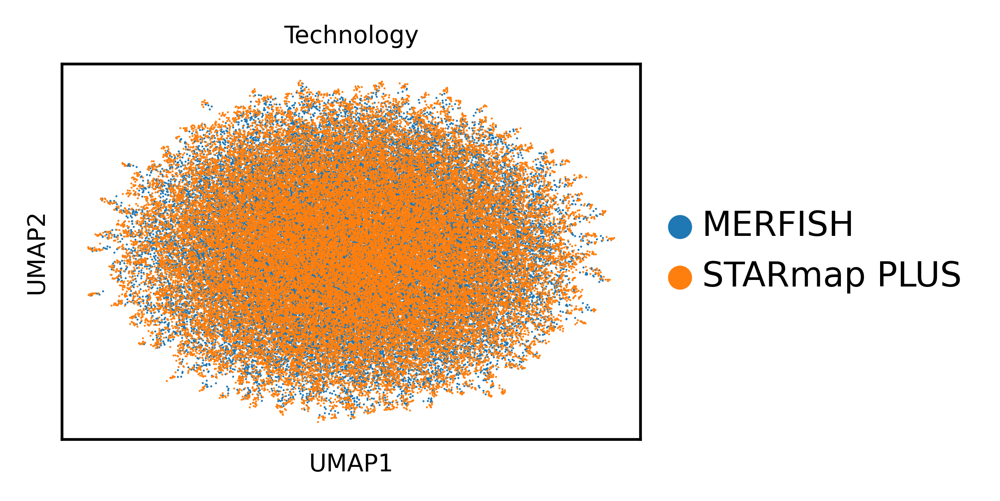

/tmp/ipykernel_3728605/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


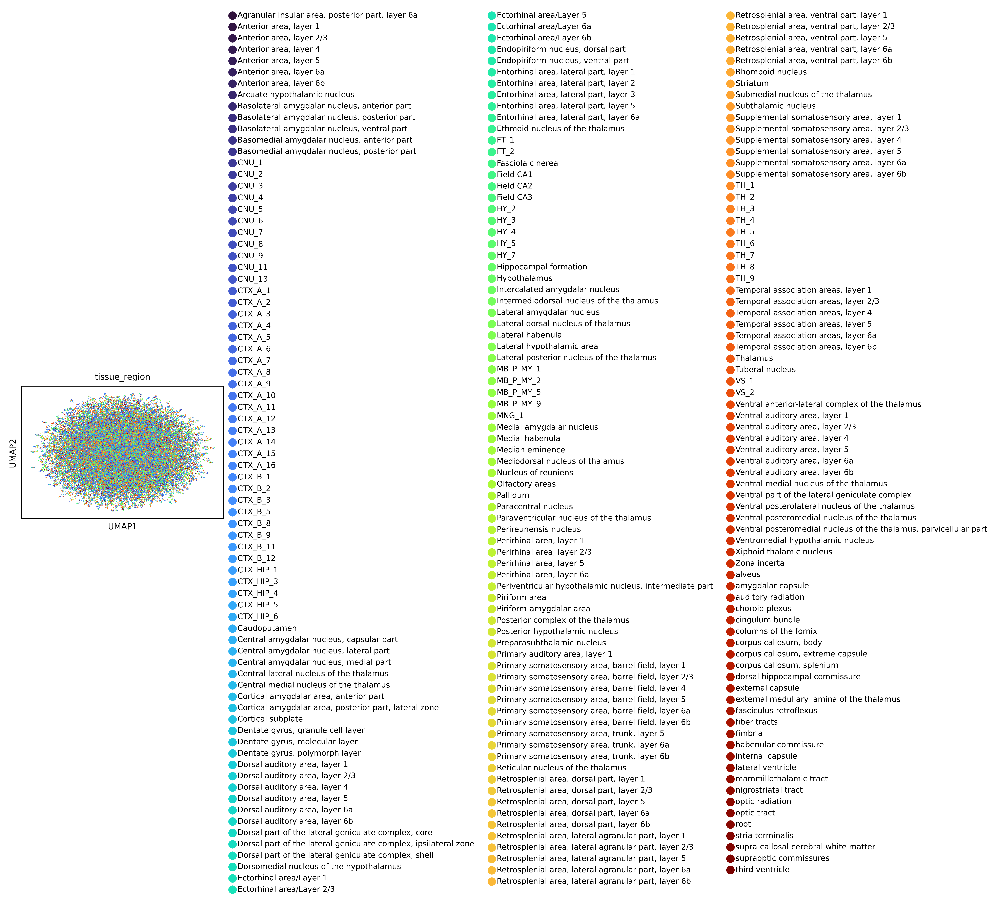

In [25]:
try:
    rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                     n_pcs=n_pcs, key_added=emb_key)
    rsc.tl.umap(adata, neighbors_key=emb_key)
except NameError:
    sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                    n_pcs=n_pcs, key_added=emb_key)
    sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [26]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [43]:
### Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

try:
    rsc.tl.leiden(adata,
                  neighbors_key=emb_key,
                  key_added=latent_cluster_key,
                  resolution=latent_leiden_resolution,
                  flavor="igraph",
                  n_iterations=2)
except NameError:
    sc.tl.leiden(adata,
                 neighbors_key=emb_key,
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution,
                 flavor="igraph",
                 n_iterations=2)

In [44]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
0     85244
1        16
2        16
4        16
5        16
6        16
10       16
7        16
8        16
9        16
12       16
11       16
13       16
14       16
23       16
15       16
16       16
17       16
18       16
19       16
20       16
21       16
29       16
24       16
28       16
26       16
3        15
22       15
25       15
27       15
Name: X_niche_embeddings_clusters_res_0.17, dtype: int64


In [45]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')

/tmp/ipykernel_3728605/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:482: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


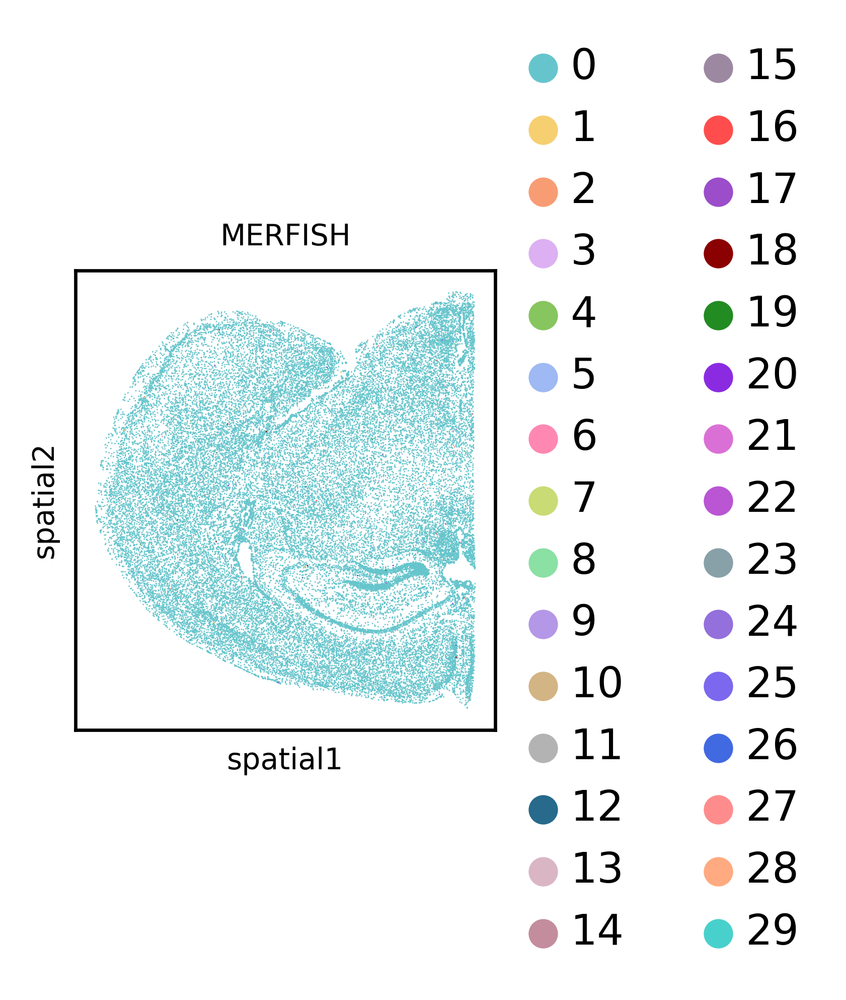

/tmp/ipykernel_3728605/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:482: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


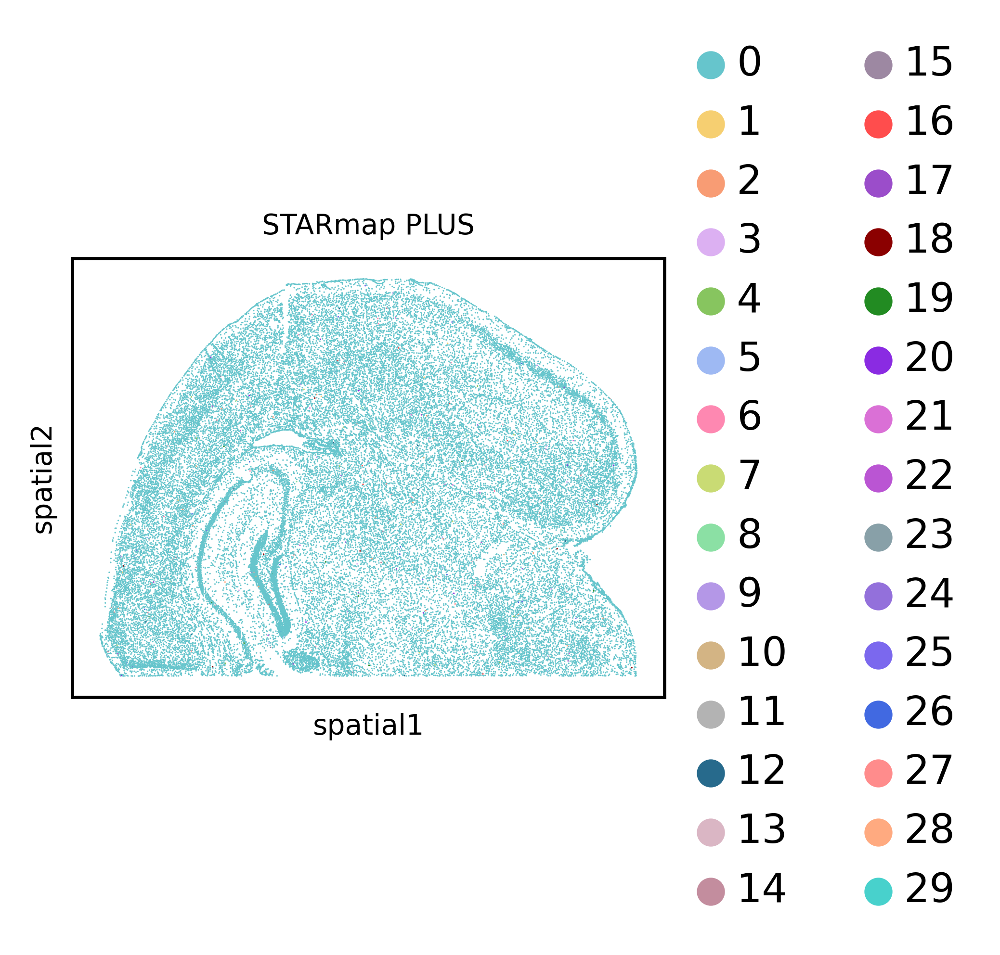

In [46]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [47]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

X_niche_embeddings average cosine similarity: 1.0001580157648042
Saved → /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/nicheformer/mmb0-1b_smb1-1b_1p_X_niche_embeddings_avg_cosine_similarity.csv


In [48]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.0059
ARI (Sub_molecular_tissue_region): -0.0000
NMI (ccf_region_name): 0.0046
ARI (ccf_region_name): -0.0000


In [51]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

iLISI: 0.9527
ASW batch: 0.0161


/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


MMD: nan


In [ ]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.6  (108 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0192  ARI=-0.0000
  ccf_region_name                           NMI=0.0440  ARI=0.0000

── Resolution 0.7  (139 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0246  ARI=0.0000
  ccf_region_name                           NMI=0.0534  ARI=-0.0000

── Resolution 0.8  (170 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0292  ARI=-0.0000
  ccf_region_name                           NMI=0.0630  ARI=0.0000

── Resolution 0.9  (192 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0328  ARI=0.0000
  ccf_region_name                           NMI=0.0694  ARI=0.0000

── Resolution 1.0  (224 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0378  ARI=0.0001
  ccf_region_name                           NMI=0.0778  ARI=-0.0000

── Resolution 1.1  (237 clusters) ──
  Sub_molecular_tissue_region               NMI=0.0395  ARI=0.0000
  ccf_region_name              